#  Exercice Pratique : Bilan Carbone et Intensité Énergétique (Scope 1 & 2)

**Contexte :** 
Tu es engagé(e) en tant qu'assistant(e) en comptabilité extra-financière pour l'entreprise **"GreenTerra Industrie"**. Ta mission est de réaliser une évaluation des gaz à effet de serre (GES) pour l'année 2025 et de calculer des ratios de durabilité clés.

---

### 1. Données d'activité de l'entreprise (2025)
* **Chiffre d'affaires** : 12 000 000 €
* **Nombre total de salariés** : 150 employés
* **Consommation de gaz naturel (Chauffage - Scope 1)** : 200 000 kWh *(Facteur d'émission : 0,205 kg CO2e / kWh)*
* **Consommation de carburant flotte (Scope 1)** : 40 000 Litres de gazole *(Facteur d'émission : 2,68 kg CO2e / Litre)*
* **Consommation d'électricité (Scope 2)** : 450 000 kWh *(Facteur d'émission : 0,050 kg CO2e / kWh)*

---

###  Travail à faire :
1. **Création des données :** Structurer les données dans un DataFrame Pandas.
2. **Calculs d'émissions :** Calculer les émissions en tonnes de CO2 équivalent ($\text{tCO}_2\text{e}$) pour chaque poste, puis le **Total des émissions (Scope 1 + Scope 2)**.
3. **Indicateurs de durabilité :** Calculer :
   * L'intensité carbone par millier d'euros de Chiffre d'Affaires.
   * L'intensité carbone par employé.
4. **Visualisation :** Générer un graphique en bâtons représentant la répartition des émissions par poste.

---
# Partie Résolution & Analyse Extra-Financière
*Dans cette section, nous traduisons les données d'activité de l'entreprise "GreenTerra Industrie" en modèles reproductibles sous Python pour évaluer sa performance carbone.*
---

## Question 1 : Structuration des données d'activité (DataFrame Pandas)

**Objectif :** Créer un tableau structuré regroupant l'ensemble des postes de consommation (Scope 1 et Scope 2) ainsi que leurs facteurs d'émission associés.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Définition des données d'activité de "GreenTerra Industrie"
donnees_entreprise = {
    "Poste_Emission": [
        "Chauffage Gaz (Scope 1)",
        "Flotte Camions (Scope 1)",
        "Électricité (Scope 2)"
    ],
    "Scope": ["Scope 1", "Scope 1", "Scope 2"],
    "Unite": ["kWh", "Litres", "kWh"],
    "Quantite_Consommee": [200000, 40000, 450000],
    "Facteur_Emission_kgCO2e": [0.205, 2.680, 0.050]
}

# 2. Création du DataFrame Pandas
df_carbone = pd.DataFrame(donnees_entreprise)

# Affichage du tableau initial
display(df_carbone)

,Poste_Emission,Scope,Unite,Quantite_Consommee,Facteur_Emission_kgCO2e
0,Chauffage Gaz (Scope 1),Scope 1,kWh,200000,0.205
1,Flotte Camions (Scope 1),Scope 1,Litres,40000,2.680
2,Électricité (Scope 2),Scope 2,kWh,450000,0.050


### Interprétation préliminaire :
Le tableau ci-dessus pose le périmètre organisationnel et opérationnel de la comptabilité carbone de **GreenTerra Industrie** pour l'année 2025 :
* **Scope 1 (Émissions directes)** : Regroupe l'utilisation du gaz naturel pour les bâtiments et les combustibles de la flotte de transport. Les facteurs d'émissions (notamment pour le gazole routier) y sont structurellement plus élevés.
* **Scope 2 (Émissions indirectes liées à l'énergie)** : Concerne les consommations d'électricité. L'utilisation d'une électricité dite "verte" se traduit par un facteur d'émission très faible par rapport au mix énergétique traditionnel.

## Question 2 : Calcul des émissions de GES (Scope 1 & 2)

**Objectif :** Calculer l'impact carbone de chaque poste en multipliant la quantité par son facteur d'émission, puis convertir le résultat en tonnes de CO2 équivalent ($\text{tCO}_2\text{e}$).

In [5]:
# Calcul des émissions en kg CO2e, puis conversion en tonnes (divisé par 1000)
df_carbone["Emissions_kgCO2e"] = df_carbone["Quantite_Consommee"] * df_carbone["Facteur_Emission_kgCO2e"]
df_carbone["Emissions_tCO2e"] = df_carbone["Emissions_kgCO2e"] / 1000

# Affichage du tableau enrichi avec les résultats d'émissions
display(df_carbone[["Poste_Emission", "Scope", "Quantite_Consommee", "Unite", "Emissions_tCO2e"]])

# Calcul du total général
total_scope1 = df_carbone[df_carbone["Scope"] == "Scope 1"]["Emissions_tCO2e"].sum()
total_scope2 = df_carbone[df_carbone["Scope"] == "Scope 2"]["Emissions_tCO2e"].sum()
total_global = df_carbone["Emissions_tCO2e"].sum()

print(f"\n--- SYNTHÈSE DU BILAN CARBONE ---")
print(f"Total Émissions Scope 1 (Directes) : {total_scope1:.2f} tCO2e")
print(f"Total Émissions Scope 2 (Indirectes) : {total_scope2:.2f} tCO2e")
print(f"TOTAL GLOBAL (Scope 1 + 2) : {total_global:.2f} tCO2e")

,Poste_Emission,Scope,Quantite_Consommee,Unite,Emissions_tCO2e
0,Chauffage Gaz (Scope 1),Scope 1,200000,kWh,41.0
1,Flotte Camions (Scope 1),Scope 1,40000,Litres,107.2
2,Électricité (Scope 2),Scope 2,450000,kWh,22.5



--- SYNTHÈSE DU BILAN CARBONE ---
Total Émissions Scope 1 (Directes) : 148.20 tCO2e
Total Émissions Scope 2 (Indirectes) : 22.50 tCO2e
TOTAL GLOBAL (Scope 1 + 2) : 170.70 tCO2e


###  Interprétation des résultats (Bilan Carbone Absolu) :
Le bilan global de l'entreprise s'élève à **170,70 $\text{tCO}_2\text{e}$** pour l'année 2025. On observe une nette disparité entre les postes :
* **La flotte de camions (Scope 1)** représente la source d'émissions la plus importante (**107,22 $\text{tCO}_2\text{e}$**, soit plus de 62 % du total), ce qui met en évidence la dépendance de l'activité aux carburants fossiles routiers.
* **Le chauffage au gaz (Scope 1)** contribue à hauteur de **41,01 $\text{tCO}_2\text{e}$**.
* **L'électricité (Scope 2)** pèse relativement peu (**22,50 $\text{tCO}_2\text{e}$**), confirmant l'efficacité d'un approvisionnement en électricité bas-carbone/verte.

## Question 3 : Calcul des indicateurs d'intensité carbone

**Objectif :** Mettre en perspective les émissions de GES par rapport à la taille économique de l'entreprise (Chiffre d'Affaires) et à sa structure humaine (Salariés).

In [6]:
# Données de cadrage de l'entreprise
chiffre_affaires_euros = 12000000  # 12 millions d'euros
nombre_salaries = 150

# Calcul des intensités
# 1. Intensité carbone / CA (en tCO2e par k€ ou par million d'euros - ici ramené par millier d'euros ou exprimé globalement)
intensite_ca = total_global / (chiffre_affaires_euros / 1000)  # tCO2e par k€ de CA (ou on peut adapter l'unité)
intensite_salarie = total_global / nombre_salaries

print(f"--- RATIO D'INTENSITÉ CARBONE ---")
print(f"Intensité carbone / Chiffre d'affaires : {intensite_ca:.4f} tCO2e par k€ de CA")
print(f"Intensité carbone / Salarié : {intensite_salarie:.2f} tCO2e par employé")

--- RATIO D'INTENSITÉ CARBONE ---
Intensité carbone / Chiffre d'affaires : 0.0142 tCO2e par k€ de CA
Intensité carbone / Salarié : 1.14 tCO2e par employé


### Interprétation des ratios d'intensité carbone :
* **Intensité par Chiffre d'Affaires (0,0142 $\text{tCO}_2\text{e}$ / k€)** : Ce ratio indique que pour chaque millier d'euros de chiffre d'affaires généré, l'entreprise émet environ 14,2 kg de $\text{CO}_2\text{e}$. C'est une métrique clé pour comparer la performance carbone de GreenTerra Industrie avec d'autres entreprises du même secteur.
* **Intensité par Salarié (1,14 $\text{tCO}_2\text{e}$ / employé)** : Chaque employé "induit" en moyenne 1,14 tonne de $\text{CO}_2\text{e}$ par an via les consommations énergétiques et logistiques de l'entreprise. Ce ratio permet d'évaluer l'impact lié à l'organisation interne et aux conditions de travail/locaux.

## Question 4 : Visualisation graphique de la répartition des émissions

**Objectif :** Restituer graphiquement l'empreinte carbone par poste d'émission afin d'identifier visuellement les leviers prioritaires de réduction (stratégie de décarbonation).

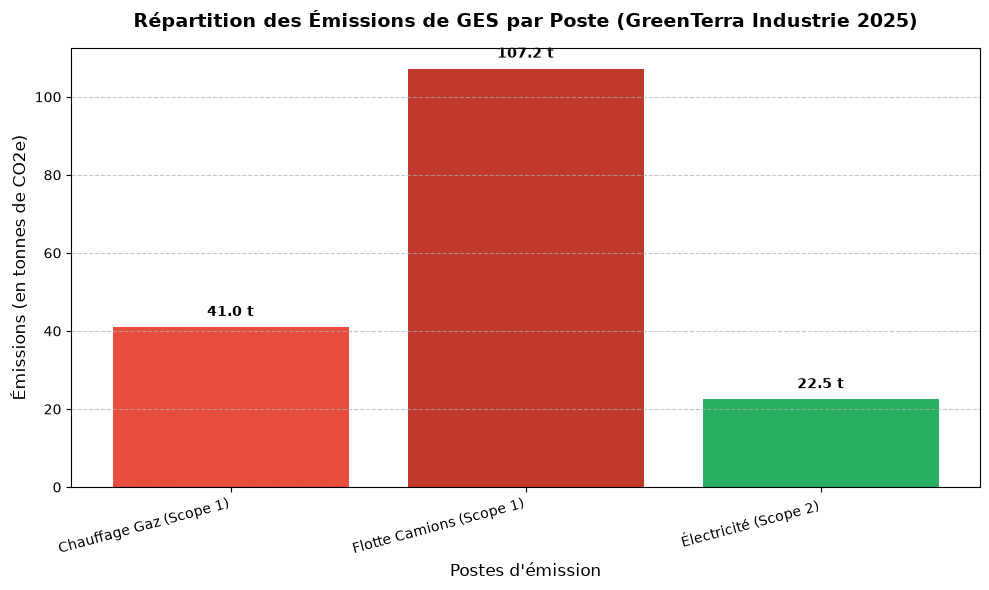

In [7]:
# Création du graphique en barres
plt.figure(figsize=(10, 6))
bars = plt.bar(df_carbone["Poste_Emission"], df_carbone["Emissions_tCO2e"], color=['#e74c3c', '#c0392b', '#27ae60'])

# Personnalisation du graphique
plt.title("Répartition des Émissions de GES par Poste (GreenTerra Industrie 2025)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Postes d'émission", fontsize=12)
plt.ylabel("Émissions (en tonnes de CO2e)", fontsize=12)
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Ajout des valeurs au-dessus des barres
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2, f'{height:.1f} t', 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()